# Módulo 4 — Práctica Día 7: series temporales, promedios espaciales y exportación

Ejercicios 1, 2, 3 y 5 de la práctica del **Día 7** (ver [`README.md`](../README.md)).
La animación (Ejercicio 4) se trabaja aparte en
[`04_entregable_animacion.ipynb`](04_entregable_animacion.ipynb). Seguimos
con el `wrfout` real recortado (Argentina/Uruguay, 2024-12-13).

> **📍 Nota para curso con 2 grupos:** el Ejercicio 1 usa el aeropuerto de **Iguazú**, una de las 6 estaciones reales dentro del dominio (`data/ogimet/coords_area_wrf.json`), compartido por toda la clase. Como refuerzo por grupo, repetir la serie puntual con otra estación:
> - **Grupo 1 (Norte):** Resistencia o Salto.
> - **Grupo 2 (Sur):** Rosario, Ezeiza o Carrasco.
> Esto adelanta directamente la validación contra estaciones del Día 8.

In [1]:
import xarray as xr
import xwrf
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

raw = xr.open_dataset("../../../data/grid_muestra/wrfout_real_muestra.nc")
ds = raw.xwrf.postprocess().xwrf.destagger()
ds

<xarray.Dataset> Size: 141MB
Dimensions:         (Time: 3, y: 786, x: 879, z: 1, x_stag: 880, y_stag: 787)
Coordinates:
  * Time            (Time) datetime64[us] 24B 2024-12-13T06:00:00 ... 2024-12...
    XTIME           (Time) datetime64[ns] 24B ...
  * y               (y) float64 6kB -4.258e+06 -4.255e+06 ... -1.903e+06
  * x               (x) float64 7kB -1.317e+06 -1.314e+06 ... 1.317e+06
    XLAT            (y, x) float32 3MB -39.47 -39.47 -39.47 ... -18.87 -18.87
    XLONG           (y, x) float32 3MB -61.2 -61.17 -61.14 ... -34.61 -34.58
    XLAT_V          (y_stag, x) float32 3MB -39.48 -39.48 ... -18.86 -18.86
    XLONG_V         (y_stag, x) float32 3MB -61.2 -61.17 ... -34.61 -34.58
  * x_stag          (x_stag) float64 7kB -1.319e+06 -1.316e+06 ... 1.318e+06
    XLAT_U          (y, x_stag) float32 3MB -39.47 -39.47 ... -18.87 -18.87
    XLONG_U         (y, x_stag) float32 3MB -61.21 -61.18 ... -34.6 -34.57
  * y_stag          (y_stag) float64 6kB -4.259e+06 -4.256e+06 ... -1.901e+06
Dimensions without coordinates: z
Data variables: (12/17)
    Times           (Time) |S19 57B b'2024-12-13_06:00:00' ... b'2024-12-13_1...
    T2              (Time, y, x) float32 8MB ...
    U10             (Time, y, x) float32 8MB ...
    V10             (Time, y, x) float32 8MB ...
    PSFC            (Time, y, x) float32 8MB ...
    Q2              (Time, y, x) float32 8MB ...
    ...              ...
    V               (Time, z, y, x) float32 8MB 2.621 2.666 ... -2.954 -2.911
    wind_east       (Time, z, y, x) float32 8MB 2.076 2.113 ... -6.66 -6.695
    wind_north      (Time, z, y, x) float32 8MB 2.621 2.666 ... -2.954 -2.911
    wind_east_10    (Time, y, x) float32 8MB 1.978 2.013 2.033 ... -6.296 -6.33
    wind_north_10   (Time, y, x) float32 8MB 2.497 2.54 2.544 ... -2.785 -2.75
    wrf_projection  object 8B +proj=merc +x_0=0 +y_0=0 +a=6370000 +b=6370000 ...
Attributes: (12/18)
    TITLE:                        OUTPUT FROM WRF V4.7.1 MODEL
    START_DATE:                  2024-12-12_00:00:00
    SIMULATION_START_DATE:       2024-12-12_00:00:00
    MAP_PROJ:                    3
    CEN_LAT:                     -29.694515
    CEN_LON:                     -47.88938
    ...                          ...
    DX:                          3000.0
    DY:                          3000.0
    WEST-EAST_GRID_DIMENSION:    880
    SOUTH-NORTH_GRID_DIMENSION:  787
    BOTTOM-TOP_GRID_DIMENSION:   50
    history:                     Subconjunto real recortado (variables de sup...

## Ejercicio 1 — Serie temporal en un punto (35 min)

Retomando el Módulo 2: como `XLAT`/`XLONG` son 2D, se busca el índice de
grilla más cercano por distancia mínima, no con `.sel(method="nearest")`
directo.

Punto de grilla más cercano: y=540, x=222 (lat=-25.738, lon=-54.467)


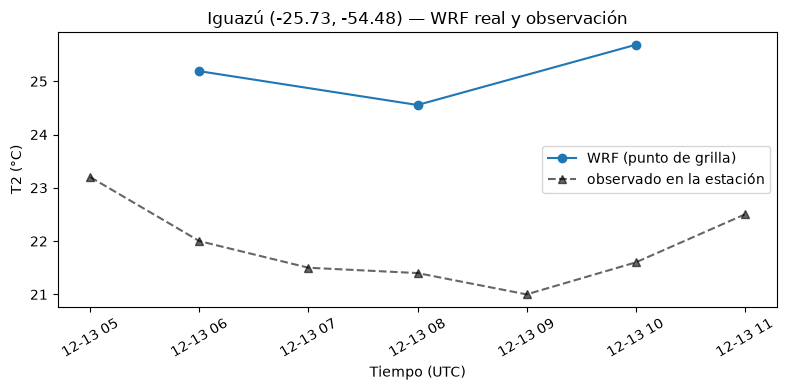

In [2]:
# Aeropuerto de Iguazú (Argentina): estación real dentro del dominio.
# En el Módulo 5 se compara el WRF contra lo que midió esta estación.
coords = json.load(open("../../../data/ogimet/coords_area_wrf.json"))
lat_punto, lon_punto = coords["Iguazu"]["lat"], coords["Iguazu"]["lon"]

dist2 = (ds["XLAT"] - lat_punto) ** 2 + (ds["XLONG"] - lon_punto) ** 2
iy, ix = np.unravel_index(np.argmin(dist2.values), dist2.shape)
print(f"Punto de grilla más cercano: y={iy}, x={ix} "
      f"(lat={float(ds['XLAT'][iy, ix]):.3f}, lon={float(ds['XLONG'][iy, ix]):.3f})")

serie_punto = (ds["T2"].isel(y=iy, x=ix) - 273.15)

# Lo que midió la estación esas mismas horas (SYNOP, cada hora)
obs = pd.read_csv("../../../data/obs/Iguazu_2024_12_13_horario.csv", parse_dates=["tiempo"])
obs = obs[(obs["tiempo"] >= "2024-12-13 05:00") & (obs["tiempo"] <= "2024-12-13 11:00")]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ds["Time"], serie_punto, marker="o", label="WRF (punto de grilla)")
ax.plot(obs["tiempo"], obs["temp_C"], "k^--", alpha=0.6, label="observado en la estación")
ax.set_xlabel("Tiempo (UTC)")
ax.set_ylabel("T2 (°C)")
ax.set_title(f"Iguazú ({lat_punto:.2f}, {lon_punto:.2f}) — WRF real y observación")
ax.legend()
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

> **Nota:** a diferencia del Módulo 2 (donde `latitude`/`longitude` eran
> coordenadas 1D y `.sel()` funcionaba directamente), aquí `XLAT`/`XLONG`
> son campos 2D — por eso se busca el índice de grilla más cercano
> manualmente (distancia mínima), en vez de usar `.sel(method="nearest")`
> sobre `y`/`x`, que están en metros de la proyección, no en grados. Con
> solo 3 pasos de tiempo reales (cada 2 h), esta serie es corta —
> suficiente para el ejercicio, pero mucho menos densa que una corrida
> completa de varios días.

## Ejercicio 2 — Promedio espacial del dominio (25 min)

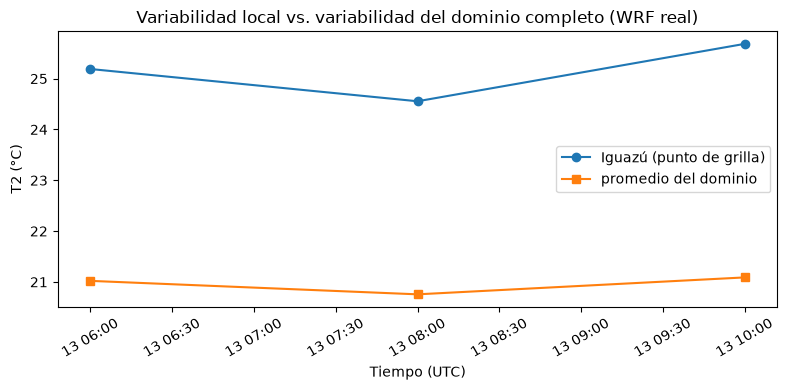

Desviación estándar en el punto:           0.462 °C
Desviación estándar del promedio espacial: 0.144 °C
(el promedio espacial suele variar menos que un punto individual, porque promedia parte del ruido/variabilidad local — un dominio real de 786x879 puntos promedia mucho ruido local)


In [3]:
promedio_espacial = (ds["T2"].mean(dim=["y", "x"]) - 273.15)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ds["Time"], serie_punto, marker="o", label="Iguazú (punto de grilla)")
ax.plot(ds["Time"], promedio_espacial, marker="s", label="promedio del dominio")
ax.set_xlabel("Tiempo (UTC)")
ax.set_ylabel("T2 (°C)")
ax.set_title("Variabilidad local vs. variabilidad del dominio completo (WRF real)")
ax.legend()
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

print(f"Desviación estándar en el punto:           {float(serie_punto.std()):.3f} °C")
print(f"Desviación estándar del promedio espacial: {float(promedio_espacial.std()):.3f} °C")
print("(el promedio espacial suele variar menos que un punto individual,",
      "porque promedia parte del ruido/variabilidad local — un dominio real de",
      "786x879 puntos promedia mucho ruido local)")

## Ejercicio 3 — La lluvia viene acumulada (30 min)

`RAINC` y `RAINNC` funcionan como el odómetro de un auto: no dicen cuánto
llovió en cada salida, sino cuánto lleva lloviendo desde que empezó la
simulación. Para saber cuánto llovió entre dos salidas hay que restar.
En este `wrfout` hay una salida cada **2 horas**, así que la resta da lluvia
en 2 horas.

Comparamos el error común (graficar el acumulado total) con el cálculo
correcto (la diferencia entre las dos últimas salidas).

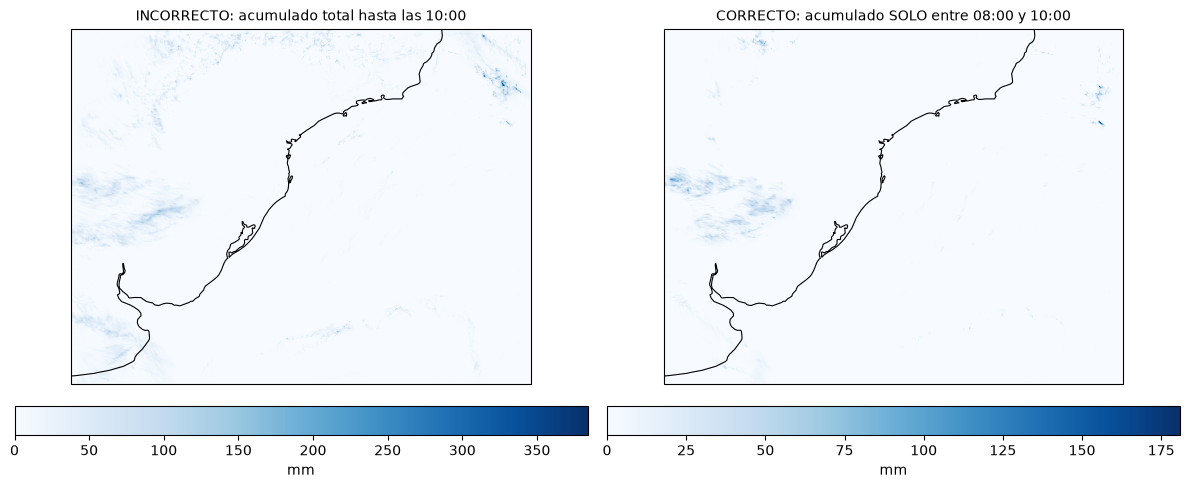

Precipitación media 'incorrecta' (acumulado total): 3.616 mm
Precipitación media CORRECTA (solo 08:00-10:00):    0.776 mm
Precipitación máxima CORRECTA en el dominio:         180.9 mm en 2 h (un evento convectivo real e intenso — no es un error de datos)


In [4]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

extent = [float(ds.XLONG.min()), float(ds.XLONG.max()), float(ds.XLAT.min()), float(ds.XLAT.max())]

precip_total = ds["RAINC"] + ds["RAINNC"]
precip_por_intervalo = precip_total.diff("Time")  # cada intervalo real es de 2 horas, no 1

# INCORRECTO: tratar el acumulado total (hasta el ultimo paso disponible) como si fuera de un solo intervalo
precip_acumulada_mal = precip_total.isel(Time=2)   # acumulado hasta las 10:00
# CORRECTO: diferencia entre los dos ultimos pasos (08:00 -> 10:00)
precip_ok = precip_por_intervalo.isel(Time=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), subplot_kw={"projection": ccrs.PlateCarree()})

for ax, campo, titulo in zip(
    axes,
    [precip_acumulada_mal, precip_ok],
    ["INCORRECTO: acumulado total hasta las 10:00", "CORRECTO: acumulado SOLO entre 08:00 y 10:00"],
):
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    m = ax.pcolormesh(ds["XLONG"], ds["XLAT"], campo, transform=ccrs.PlateCarree(),
                       cmap="Blues", shading="auto", vmin=0)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
    ax.set_title(titulo, fontsize=10)
    plt.colorbar(m, ax=ax, orientation="horizontal", pad=0.05, label="mm")

fig.tight_layout()
plt.savefig("mapa_precipitacion.png", dpi=100)
plt.show()

print(f"Precipitación media 'incorrecta' (acumulado total): {float(precip_acumulada_mal.mean()):.3f} mm")
print(f"Precipitación media CORRECTA (solo 08:00-10:00):    {float(precip_ok.mean()):.3f} mm")
print(f"Precipitación máxima CORRECTA en el dominio:         {float(precip_ok.max()):.1f} mm en 2 h",
      "(un evento convectivo real e intenso — no es un error de datos)")

## Ejercicio 5 — Exportación de productos derivados (30 min)

In [5]:
precip_por_intervalo = (ds["RAINC"] + ds["RAINNC"]).diff("Time").drop_vars(["XLAT", "XLONG", "XTIME"], errors="ignore")
precip_por_intervalo.name = "precipitacion_2h"
precip_por_intervalo.attrs = {"units": "mm", "long_name": "Precipitación acumulada cada 2 h (RAINC+RAINNC diferenciada)"}

serie_punto_exp = serie_punto.drop_vars(["XLAT", "XLONG", "XTIME"], errors="ignore").assign_attrs(
    units="degC", long_name="T2 en el punto de grilla más cercano a Iguazú")
promedio_espacial_exp = promedio_espacial.drop_vars(["XLAT", "XLONG", "XTIME"], errors="ignore").assign_attrs(
    units="degC", long_name="T2 promedio espacial del dominio")

productos = xr.Dataset({
    "precipitacion_2h": precip_por_intervalo,
    "t2_punto_ciudad": serie_punto_exp,
    "t2_promedio_dominio": promedio_espacial_exp,
})
productos.attrs["title"] = "Productos derivados del Módulo 4 (WRF real, proyecto bigua, 2024-12-13)"

productos.to_netcdf("productos_modulo4.nc")
print("Archivo exportado: productos_modulo4.nc")
productos

Archivo exportado: productos_modulo4.nc


<xarray.Dataset> Size: 8MB
Dimensions:              (Time: 3, x: 879, y: 786)
Coordinates:
  * Time                 (Time) datetime64[us] 24B 2024-12-13T06:00:00 ... 20...
  * x                    (x) float64 7kB -1.317e+06 -1.314e+06 ... 1.317e+06
  * y                    (y) float64 6kB -4.258e+06 -4.255e+06 ... -1.903e+06
Data variables:
    precipitacion_2h     (Time, y, x) float32 8MB nan nan nan ... 0.0 0.0 0.0
    t2_punto_ciudad      (Time) float32 12B 25.19 24.55 25.68
    t2_promedio_dominio  (Time) float32 12B 21.02 20.76 21.09
Attributes:
    title:    Productos derivados del Módulo 4 (WRF real, proyecto bigua, 202...

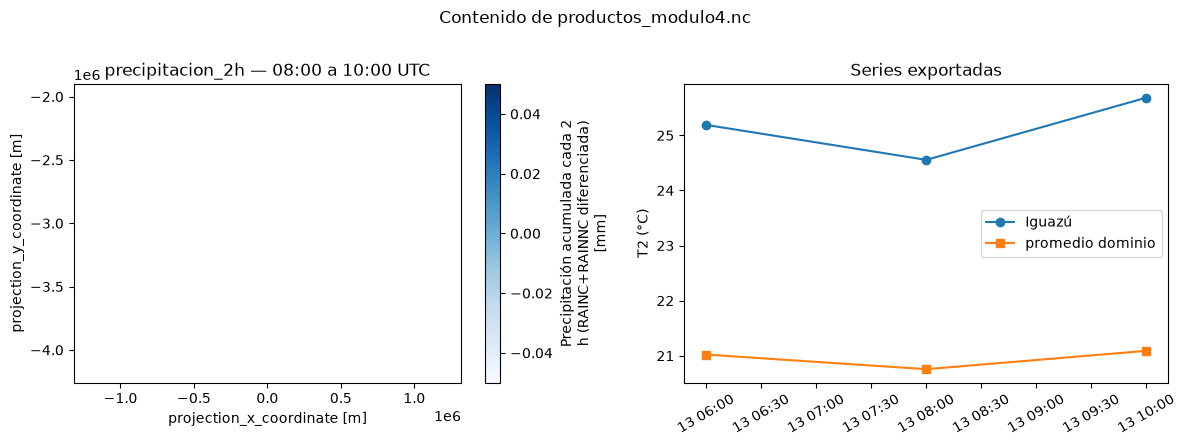

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
productos["precipitacion_2h"].isel(Time=0).plot(ax=axes[0], cmap="Blues")
axes[0].set_title("precipitacion_2h — 08:00 a 10:00 UTC")

axes[1].plot(productos["Time"], productos["t2_punto_ciudad"], marker="o", label="Iguazú")
axes[1].plot(productos["Time"], productos["t2_promedio_dominio"], marker="s", label="promedio dominio")
axes[1].set_ylabel("T2 (°C)")
axes[1].set_title("Series exportadas")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=30)

fig.suptitle("Contenido de productos_modulo4.nc")
fig.tight_layout()
plt.show()

## Cierre

Entregable parcial: este notebook + `mapa_precipitacion.png` +
`productos_modulo4.nc`. Continuar con
[`04_entregable_animacion.ipynb`](04_entregable_animacion.ipynb).